# 1. Exploratory Data Analysis: Blood Liquid Biopsy (PRJNA795275)
### Simple Plain-English Walkthrough

**What is this dataset?**  
This dataset contains real blood plasma samples from **69 people** collected by doctors at Stanford University.
- Some people are completely **Healthy** (28 people).
- Some people have **Lung Nodules / Early Lung Cancer** found on chest screening scans (29 people).
- Some people have **Small-Cell Lung Cancer** (11 people).

**What is cell-free DNA (cfDNA)?**  
When cells naturally grow old and die, they break open and dump tiny cut-up pieces of their DNA into our bloodstream.  
In a cancer patient, the tumor also dumps tiny fragments of tumor DNA into the blood. By testing a tube of blood, we try to detect if cancer is present without needing invasive surgery!

In [1]:
# Step 1: Load standard Python tools for looking at tables and making charts
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set clean chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## Step 1: Open and Look at the Patient Table

In [2]:
# Read the clean sample sheet table
manifest_file = Path("../../data/metadata/sample_sheet.csv")
df = pd.read_csv(manifest_file)

print(f"Total blood tests recorded: {len(df)}")
print(f"Total unique people (donors): {df['patient_id'].nunique()}")

# Show the first 5 rows
df[["sample_id", "patient_id", "condition", "cancer_type", "sex", "age", "bytes"]].head()

Total blood tests recorded: 69
Total unique people (donors): 62


,sample_id,patient_id,condition,cancer_type,sex,age,bytes
0,SRR17478151,CTR1,Healthy,Healthy,male,56,2.849836e+09
1,SRR17478152,CTR18,Healthy,Healthy,female,70,2.793551e+09
2,SRR17478153,CTR17,Healthy,Healthy,male,66,2.729902e+09
3,SRR17478154,CTR13,Healthy,Healthy,male,29,1.068331e+10
4,SRR17478155,CTR130,Healthy,Healthy,female,not applicable,1.006668e+10


## Step 2: Who is in our study? (Healthy vs. Cancer)
Let's see how many healthy people and how many cancer patients we have.

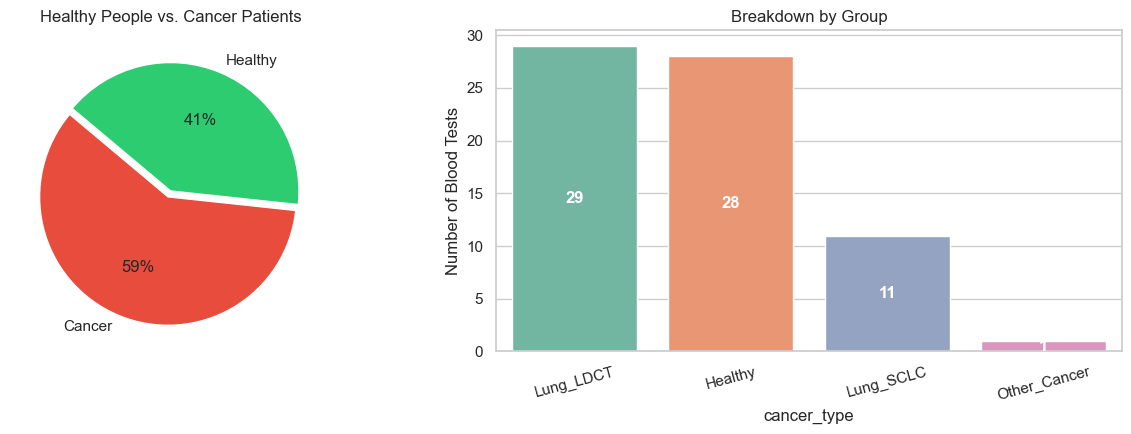

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Simple Pie Chart of Healthy vs Cancer
cond_counts = df["condition"].value_counts()
axes[0].pie(cond_counts, labels=cond_counts.index, autopct="%1.0f%%", 
            colors=["#e74c3c", "#2ecc71"], startangle=140, explode=[0.05, 0])
axes[0].set_title("Healthy People vs. Cancer Patients")

# 2. Bar Chart of the specific cancer types
type_counts = df["cancer_type"].value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, ax=axes[1], hue=type_counts.index, palette="Set2", legend=False)
axes[1].set_title("Breakdown by Group")
axes[1].set_ylabel("Number of Blood Tests")
axes[1].tick_params(axis="x", rotation=15)

# Put the numbers on top of each bar so it is easy to read
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold", fontsize=12)

plt.tight_layout()
plt.show()

## Step 3: The 'Patient Replicate' Problem (Preventing Cheating / Data Leakage)
**In simple words:**  
Imagine Patient 13 had 2 blood tests taken on different days.  
If we accidentally put Blood Test #1 into the AI's **study guide (training set)** and Blood Test #2 into the AI's **exam (test set)**, the AI will get 100% just because it recognized Patient 13's personal DNA!  
That is cheating (called **data leakage**).  

Let's count how many patients have multiple blood tests so we can protect against this.

There are 7 patients who gave multiple blood samples:
  - Patient 'CTR13': 2 blood tests
  - Patient 'LDCT50': 2 blood tests
  - Patient 'SCLC881': 2 blood tests
  - Patient 'SCLC878': 2 blood tests
  - Patient 'SCLC697': 2 blood tests
  - Patient 'SCLC565': 2 blood tests
  - Patient 'SCLC564': 2 blood tests


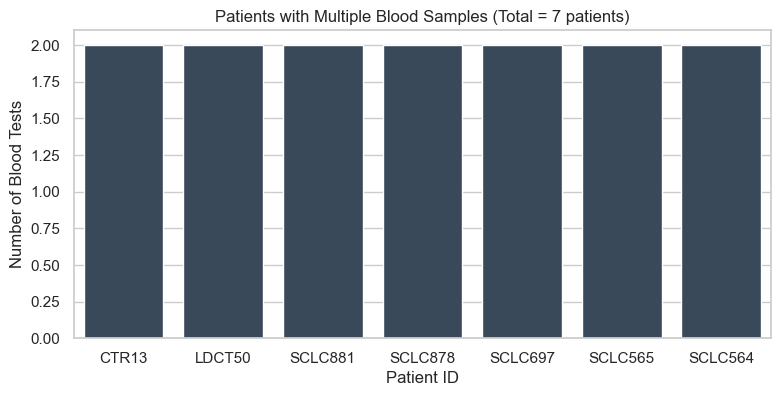

SOLUTION: We use GroupKFold on 'patient_id' so all tests from the same person stay together!


In [4]:
# Find patients with 2 or more blood tests
patient_counts = df["patient_id"].value_counts()
repeat_patients = patient_counts[patient_counts > 1]

print(f"There are {len(repeat_patients)} patients who gave multiple blood samples:")
for pt, cnt in repeat_patients.items():
    print(f"  - Patient '{pt}': {cnt} blood tests")

plt.figure(figsize=(9, 4))
sns.barplot(x=repeat_patients.index, y=repeat_patients.values, color="#34495e")
plt.title(f"Patients with Multiple Blood Samples (Total = {len(repeat_patients)} patients)")
plt.xlabel("Patient ID")
plt.ylabel("Number of Blood Tests")
plt.show()
print("SOLUTION: We use GroupKFold on 'patient_id' so all tests from the same person stay together!")

## Step 4: Demographics (Male vs. Female & Age)
Let's see the basic demographics of the people in the dataset.

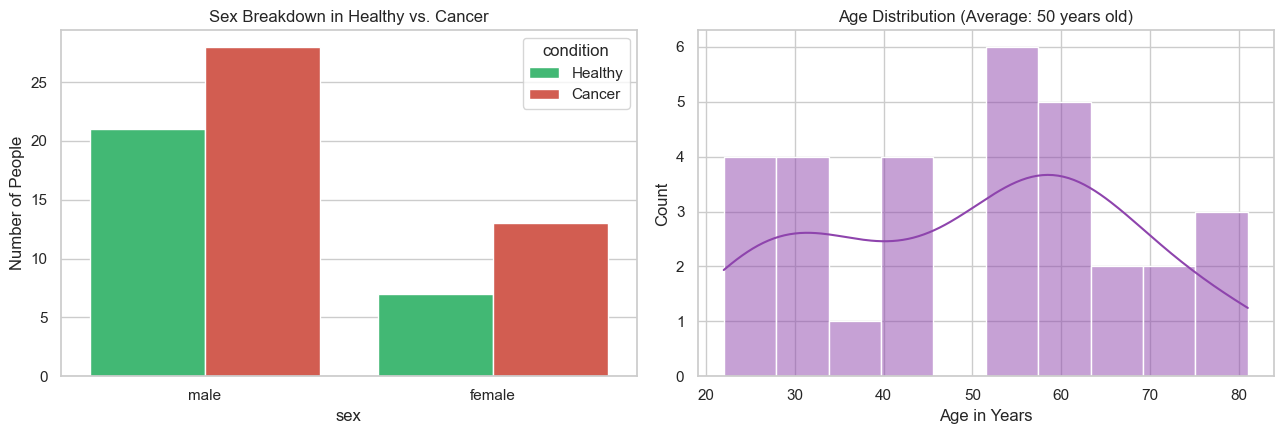

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Male vs Female
sns.countplot(data=df, x="sex", hue="condition", ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Sex Breakdown in Healthy vs. Cancer")
axes[0].set_ylabel("Number of People")

# 2. Age
valid_ages = pd.to_numeric(df["age"], errors="coerce").dropna()
sns.histplot(valid_ages, bins=10, kde=True, color="#8e44ad", ax=axes[1])
axes[1].set_title(f"Age Distribution (Average: {valid_ages.mean():.0f} years old)")
axes[1].set_xlabel("Age in Years")

plt.tight_layout()
plt.show()

## Step 5: How much DNA data do we have per sample?
Each blood test was read by an Illumina DNA sequencing machine.  
Let's check how big each sequencing file is in Gigabytes (GB).

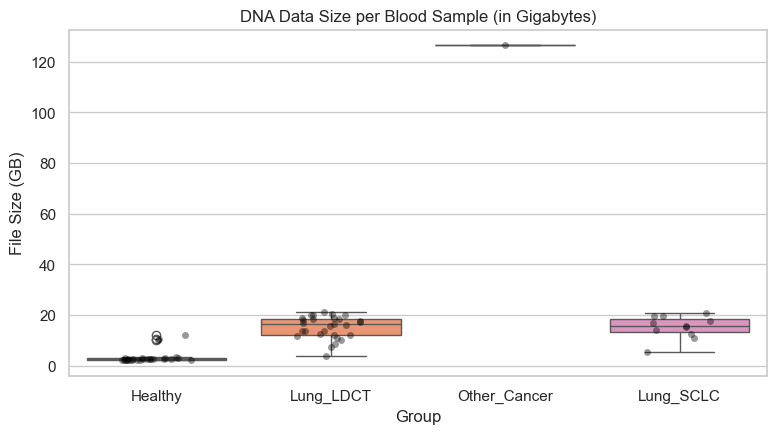

Median file size: 11.85 GB per patient.
This is low-pass whole genome sequencing (~1x to 2x depth), which is cheap and practical for clinics!


In [6]:
df["file_size_gb"] = df["bytes"] / 1e9

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="cancer_type", y="file_size_gb", palette="Set2", hue="cancer_type", legend=False)
sns.stripplot(data=df, x="cancer_type", y="file_size_gb", color="black", alpha=0.4, jitter=0.2)
plt.title("DNA Data Size per Blood Sample (in Gigabytes)")
plt.xlabel("Group")
plt.ylabel("File Size (GB)")
plt.show()

print(f"Median file size: {df['file_size_gb'].median():.2f} GB per patient.")
print("This is low-pass whole genome sequencing (~1x to 2x depth), which is cheap and practical for clinics!")

## Summary of Notebook 1:
1. **69 total blood tests** across **62 unique patients**.
2. **28 Healthy controls** give us our clean baseline plasma.
3. **41 Cancer samples** (including 29 screen-detected early lung nodules) give us our cancer signal.
4. Several patients have multiple samples, proving we **must group by patient ID** to prevent cheating.
5. In the next notebooks, we see what pure cancer tissue looks like, and then compare blood vs. tissue!